# Metrik per kategori soal: yes/no vs open-ended

Lanjutan dari `answer-result-metrics-analysis.ipynb`, tapi sumbu
perbandingannya diganti jadi **kategori soal** alih-alih embedding/reasoning
model, dan dikunci ke satu konfigurasi (`embedding_model = qwen06b`,
`llm_reasoning_model = gpt-oss-120b`) supaya ketiga metode (`agent`,
`pgvector`, `neo4j`) dibandingkan pada kondisi yang sama persis.

Kategori soal disusun dua level, parent dan child:

- **yes_no** - soal dengan jawaban ya/tidak, dipecah dari kolom `question`:
  - **regular** - bukan hard negative maupun multihop.
  - **hard_negative** - `is_hard_negative = true` dan bukan multihop.
  - **multihop** - `is_multi_hop = true`, baik dari soal regular maupun hard negative.
- **open_ended** - soal `is_open_ended = true`, dipecah berdasarkan flag soal:
  - **regular** - bukan relationship discovery, impact analysis, atau cross platform.
  <!-- - **relationship_discovery** - `is_relationship_discovery = true`.
  - **impact_analysis** - `is_impact_analysis = true`. -->
  - **cross_platform** - `is_cross_platform = true`.

Soal yes/no yang error (`is_correct` `NULL`) tetap dihitung **salah**, sama
seperti di notebook sebelumnya.

Soal **open-ended** tidak punya jawaban yes/no, jadi precision/recall/F1
tidak berlaku -- hanya **accuracy** (fraksi `answer_result.is_correct = true`,
hasil judge dari `classify-open-ended-correct.ipynb`) yang dihitung untuk
tiap child category-nya.

In [13]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2
from dotenv import load_dotenv
from sklearn.metrics import precision_recall_fscore_support

REPO_ROOT = Path.cwd().parent
load_dotenv(REPO_ROOT / ".env")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 10.5,
})

# Fixed hue per method, used consistently across every chart in this notebook.
METHOD_ORDER = ["agent", "pgvector", "neo4j"]
METHOD_COLOR = {
    "agent": "#2a78d6",
    "pgvector": "#eb6834",
    "neo4j": "#1baf7a",
}

EMBEDDING_MODEL = "qwen06b"
REASONING_MODEL = "gpt-oss-120b"

# Two-level category hierarchy: parent -> ordered child categories.
CATEGORY_HIERARCHY = {
    "yes_no": ["regular", "hard_negative", "multihop"],
}
CATEGORY_ORDER = [
    (parent, child) for parent, children in CATEGORY_HIERARCHY.items() for child in children
]


def connect():
    conn_str = os.getenv("PG_CONNECTION_STRING")
    if conn_str:
        return psycopg2.connect(conn_str)
    return psycopg2.connect(host="localhost", dbname="docs", user="postgres", password="password")

## Memuat soal yes/no dari Postgres

In [14]:
yes_no_query = """
    SELECT
        ar.method,
        ar.is_correct,
        q.question,
        q.answer,
        q.is_hard_negative,
        q.is_multi_hop
    FROM answer_result ar
    JOIN question q ON q.id = ar.question_id
    WHERE ar.embedding_model = %(embedding_model)s
      AND ar.llm_reasoning_model = %(reasoning_model)s
"""
with connect() as conn:
    df = pd.read_sql(yes_no_query, conn, params={
        "embedding_model": EMBEDDING_MODEL,
        "reasoning_model": REASONING_MODEL,
    })

print(f"{len(df)} baris soal yes/no ({EMBEDDING_MODEL} / {REASONING_MODEL})")
df.head()

1059 baris soal yes/no (qwen06b / gpt-oss-120b)


/var/folders/6s/4n20n38x5y571387phy8c5lc0000gn/T/ipykernel_36804/3232385461.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(yes_no_query, conn, params={


,method,is_correct,question,answer,is_hard_negative,is_multi_hop
0,agent,True,May loan rules in the ILS use the check-out lo...,1.0,True,False
1,agent,False,Describe the alerting and monitoring capabilit...,NaN,False,False
2,neo4j,False,What is impacted if the password recovery proh...,NaN,False,False
3,pgvector,True,What changes if the Rules of Suppression in BR...,NaN,False,False
4,neo4j,False,Describe the alerting and monitoring capabilit...,NaN,False,False


In [15]:
# q.answer is NULL for open-ended questions (they're judged separately below via open_df),
# so drop those rows here before casting to int.
df = df[df["answer"].notna()].copy()

df["is_multi_hop"] = df["is_multi_hop"].fillna(False)


def categorize(row) -> str:
    if row["is_multi_hop"]:
        return "multihop"
    if row["is_hard_negative"]:
        return "hard_negative"
    return "regular"


df["parent"] = "yes_no"
df["category"] = df.apply(categorize, axis=1)

df["answer"] = df["answer"].astype(int)
df["is_correct"] = df["is_correct"].fillna(False)
df["predicted"] = np.where(df["is_correct"], df["answer"], 1 - df["answer"])

print(df.groupby("category").size().reindex(CATEGORY_HIERARCHY["yes_no"]))

category
regular          207
hard_negative    159
multihop          93
dtype: int64


Jumlah soal per child category (parent `yes_no`) sama untuk ketiga metode
(satu set soal yang sama, cuma jawaban modelnya yang beda), jadi cukup
dicek sekali lewat `question`:

In [16]:
(
    df[df["method"] == "agent"]
    .groupby("category")
    .size()
    .reindex(CATEGORY_HIERARCHY["yes_no"])
    .rename("n_soal")
)

category
regular          69
hard_negative    53
multihop         31
Name: n_soal, dtype: int64

## Metrik accuracy / precision / recall / F1 per kategori

In [17]:
def compute_metrics(group: pd.DataFrame) -> pd.Series:
    precision, recall, f1, _ = precision_recall_fscore_support(
        group["answer"], group["predicted"], average="binary", pos_label=1, zero_division=0
    )
    return pd.Series({
        "accuracy": group["is_correct"].mean(),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "n": len(group),
    })


yes_no_metrics = (
    df.groupby(["parent", "category", "method"])
    .apply(compute_metrics, include_groups=False)
    .reset_index()
)


category_metrics = pd.concat(
    [yes_no_metrics],
    ignore_index=True,
)

category_index = pd.MultiIndex.from_tuples(CATEGORY_ORDER, names=["parent", "category"])
(
    category_metrics
    .pivot(index=["parent", "category"], columns="method", values=["accuracy", "precision", "recall", "f1", "n"])
    .reindex(category_index)
)

accuracy                     precision            \
method                   agent     neo4j  pgvector     agent     neo4j   
parent category                                                          
yes_no regular        0.942029  0.884058  0.956522  0.955556  0.930233   
       hard_negative  0.830189  0.886792  0.905660  0.619048  0.700000   
       multihop       0.903226  0.774194  0.967742  0.928571  0.900000   

                                  recall                           f1  \
method                pgvector     agent     neo4j pgvector     agent   
parent category                                                         
yes_no regular        0.937500  0.955556  0.888889      1.0  0.955556   
       hard_negative  0.736842  0.928571  1.000000      1.0  0.742857   
       multihop       0.937500  0.866667  0.600000      1.0  0.896552   

                                             n                 
method                   neo4j  pgvector agent neo4j pgvector  
parent category                                                
yes_no regular        0.909091  0.967742  69.0  69.0     69.0  
       hard_negative  0.823529  0.848485  53.0  53.0     53.0  
       multihop       0.720000  0.967742  31.0  31.0     31.0

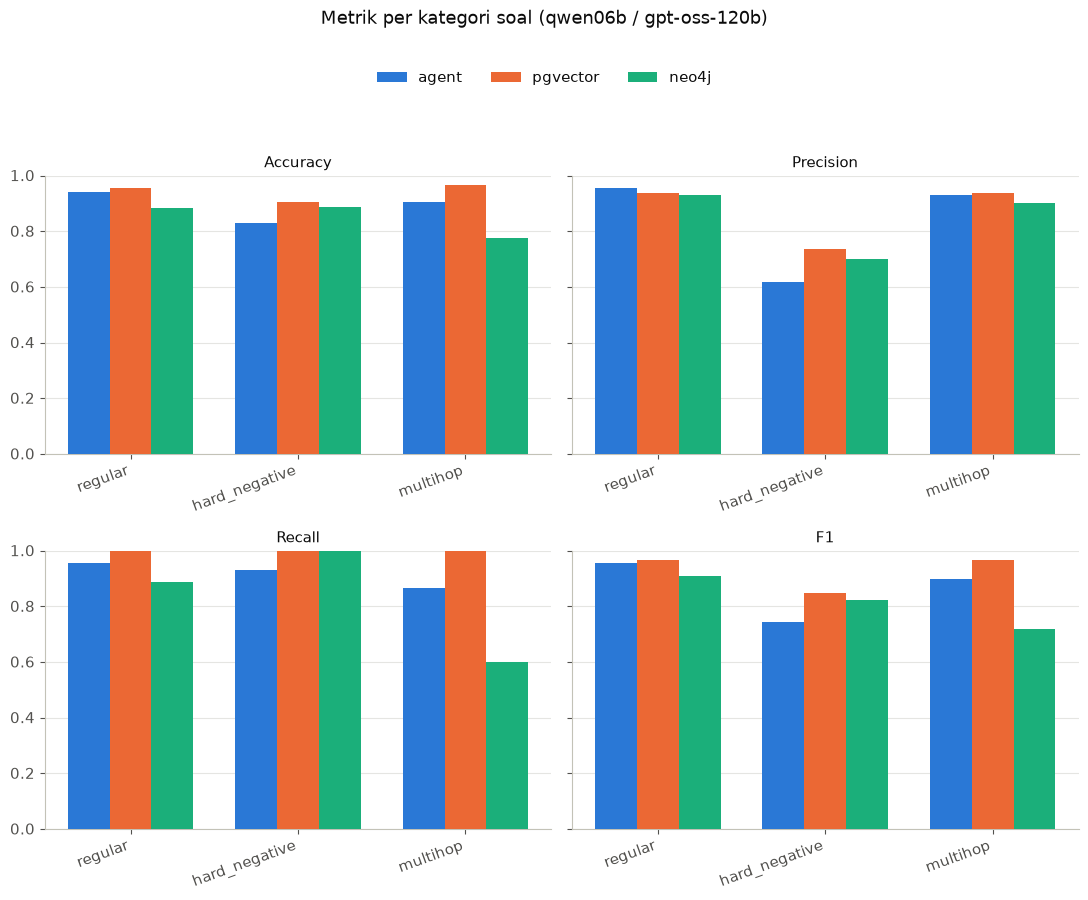

In [18]:
def plot_metric_grid(metrics_df, category_order, title):
    """2x2 grid (accuracy/precision/recall/F1), grouped bars colored by method."""
    metric_names = ["accuracy", "precision", "recall", "f1"]
    x = np.arange(len(category_order))
    bar_width = 0.25
    labels = [c for _, c in category_order]

    fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
    for ax, metric in zip(axes.flat, metric_names):
        for i, method in enumerate(METHOD_ORDER):
            sub = metrics_df[metrics_df["method"] == method].set_index(["parent", "category"])
            values = [sub.loc[pc, metric] if pc in sub.index else np.nan for pc in category_order]
            ax.bar(
                x + (i - 1) * bar_width, values, width=bar_width,
                label=method, color=METHOD_COLOR[method], zorder=3,
            )
        ax.set_title(metric.capitalize(), fontsize=11)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=20, ha="right")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", color="#e5e5e2", linewidth=0.8, zorder=0)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    handles, labels_ = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels_, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06), frameon=False)
    fig.suptitle(title, y=1.12, fontsize=13)
    fig.tight_layout()
    plt.show()


plot_metric_grid(
    category_metrics, CATEGORY_ORDER,
    f"Metrik per kategori soal ({EMBEDDING_MODEL} / {REASONING_MODEL})",
)